What is the class balance?
What accuracy would a model get by always predicting the majority class? Remember this number; it is your sanity-check baseline.

In [5]:
import numpy
import pandas
import torch
import matplotlib
from sklearn.datasets import fetch_openml

adult_data = fetch_openml(name='adult', version=2, as_frame=True) # as_frame=True will turn data into pandas DataFrame
df = adult_data.frame

rows, cols = df.shape
y = df['class']
x = df.drop(columns=['class'])
print(f"Amount of Rows: {rows}, Columns: {cols}")

numeric_cols = df.select_dtypes(include='number').columns
categorical_cols = x.select_dtypes(exclude='number').columns
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

df.replace('?', numpy.nan) # replaces huh? into NaN so isna() `ll find them
# finding NaNs:
missing_values = df.isna().sum() # copied from tg
print(missing_values[missing_values > 0])

print(df['class'].value_counts(normalize=True)) # copied from tg
print(df.describe())
df.info()


Amount of Rows: 48842, Columns: 15
Numeric: Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='str')
Categorical: Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='str')
workclass         2799
occupation        2809
native-country     857
dtype: int64
class
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64
                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  48842.000000  4.884200e+04   48842.000000  48842.000000  48842.000000   
mean      38.643585  1.896641e+05      10.078089   1079.067626     87.502314   
std       13.710510  1.056040e+05       2.570973   7452.019058    403.004552   
min       17.000000  1.228500e+04       1.000000      0.000000      0.000000   
25%       28.000000  1.175505e+05       9.000000      0.000000      0.000000   
50%       37.000000  1.781445e+05      10.00000

Right now we can answer some given questions:
1. **How many rows and columns are there?** 48842 rows and 15 columns
2. **Which columns are numeric and which are categorical?** I separated them into two lines of variables: one that includes all numeric data (numbers), and categorical includes everything that's left (text)
3. **How many values are missing, and in which columns?** In upper result, in last part, you can see "Non-Null Count" that counts every known feature. We have missing data in workclass, occupation and native-country


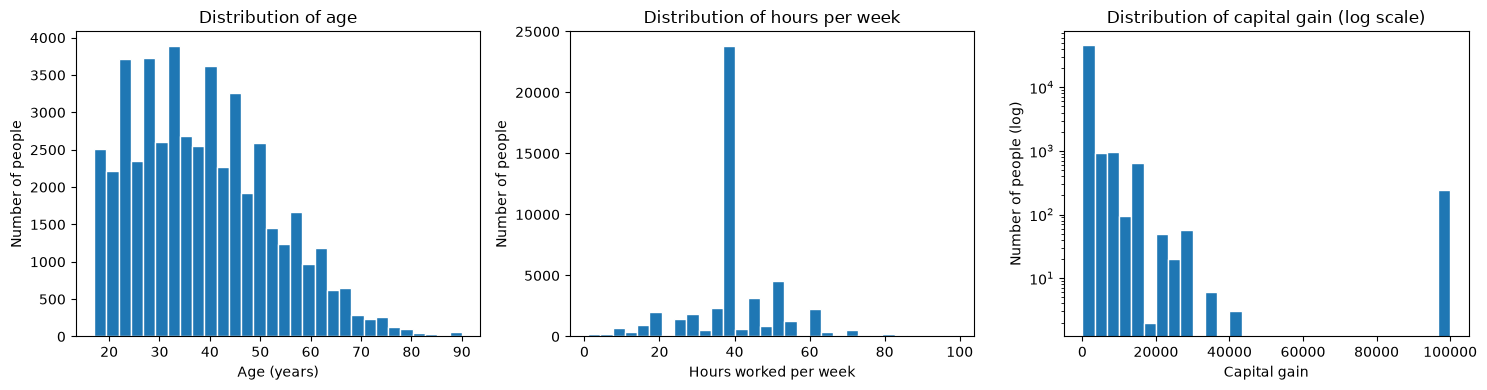

0.9173866754023177


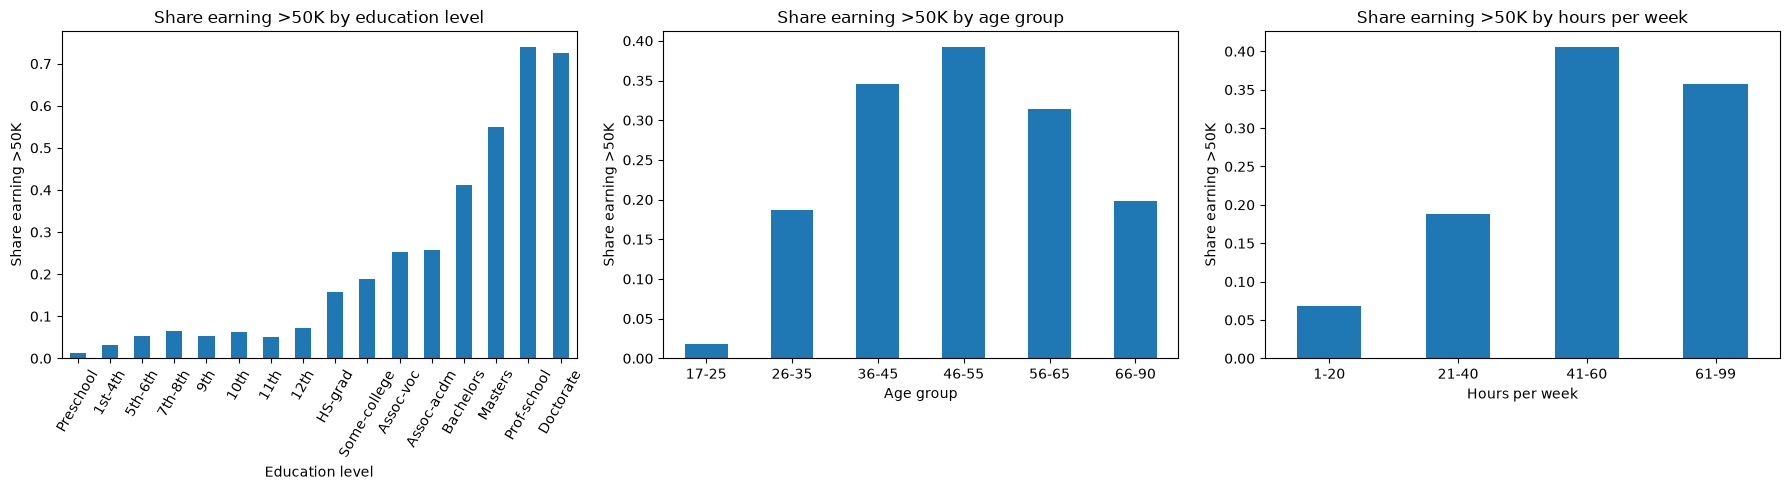

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(x['age'], bins=30, edgecolor='white')
axes[0].set_title('Distribution of age')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Number of people')

axes[1].hist(x['hours-per-week'], bins=30, edgecolor='white')
axes[1].set_title('Distribution of hours per week')
axes[1].set_xlabel('Hours worked per week')
axes[1].set_ylabel('Number of people')

axes[2].hist(x['capital-gain'], bins=30, edgecolor='white')
axes[2].set_yscale('log')
# did log scale on the y-axis since the huge bar at 0 would otherwise flatten all other bars
axes[2].set_title('Distribution of capital gain (log scale)')
axes[2].set_xlabel('Capital gain')
axes[2].set_ylabel('Number of people (log)')

plt.tight_layout() # for spacing
plt.show()

print((x['capital-gain'] == 0).mean())
# x['capital-gain'] == 0 gives true/false per row and .mean() treats True as 1





y_bin = (y == '>50K').astype(int)
# y == '>50K' gives true/false for each person and .astype(int) turns it into 1 or 0.

edu_order = (x[['education', 'education-num']]
             .drop_duplicates()
             .sort_values('education-num')
             ['education'].tolist())
# did this so edu names would be in "PreSchool to PhD" order

share_edu = y_bin.groupby(x['education'], observed=True).mean().reindex(edu_order)

age_groups = pd.cut(x['age'], bins=[16, 25, 35, 45, 55, 65, 90], labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66-90']) # pd.cut puts each age into an interval

share_age = y_bin.groupby(age_groups, observed=True).mean()

hours_groups = pd.cut(x['hours-per-week'], bins=[0, 20, 40, 60, 100], labels=['1-20', '21-40', '41-60', '61-99'])
share_hours = y_bin.groupby(hours_groups, observed=True).mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

share_edu.plot(kind='bar', ax=axes[0])
axes[0].set_title('Share earning >50K by education level')
axes[0].set_xlabel('Education level')
axes[0].set_ylabel('Share earning >50K')
axes[0].tick_params(axis='x', rotation=60) # rotated long labels so they don't overlap

share_age.plot(kind='bar', ax=axes[1])
axes[1].set_title('Share earning >50K by age group')
axes[1].set_xlabel('Age group')
axes[1].set_ylabel('Share earning >50K')
axes[1].tick_params(axis='x', rotation=0)

share_hours.plot(kind='bar', ax=axes[2])
axes[2].set_title('Share earning >50K by hours per week')
axes[2].set_xlabel('Hours per week')
axes[2].set_ylabel('Share earning >50K')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Let's analyse what we see, keeping main questions in mind:
By task, I have to find two features that look useful and two that look useless or suspicious, with having to explain why.
First that comes into view is a vast jump in numbers in hours-per-week diagram: most people work almost 40 hours a week.
Capital-gain is mostly zero, which can mean that people don't have spare money to spend, so they fall into <50K category.

We could put these two features into useful category.
Moving onto almost useless features, distribution of age does not give us info that we need, outside of giving us info on when people start retiring.


Now, naming at least one fairness or ethics concern that this dataset raises (for example, sensitive attributes such as sex, race or marital status).
Sex and race of person, unfortunately, socially affects their career, how they will be seen as a specialist in their field, and of course how they will be paid. I have to admit that these features do may benefit them in rare instances, but it's still a sensitive subject for many.
Marital status of a person may benefit them in their career, if their spouse takes care of everything else (household, children, etc)

In [10]:
pd.crosstab(x['education'], x['education-num'])

education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,1389,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,1812,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,657,0,0,0,0,0,0,0,0
1st-4th,0,247,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,509,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,955,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,756,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,1601,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,2061,0,0,0,0,0


Now, we are presented with two separate data touching education.
Education and education-num look redundant. The crosstab shows that each of the 16 education levels maps to exactly one number (for example, all “Bachelors” rows have education-num 13), so the two columns carry the same information. Keeping both adds no new signal and makes linear models harder to interpret, because the effect is split between two correlated features. I would keep education-num, since it is already ordered and numeric, and mark education as useless info.

In [8]:
df['fnlwgt'].describe()

count    4.884200e+04
mean     1.896641e+05
std      1.056040e+05
min      1.228500e+04
25%      1.175505e+05
50%      1.781445e+05
75%      2.376420e+05
max      1.490400e+06
Name: fnlwgt, dtype: float64

fnlwgt (which is "Final weight" - the number of units in the target population that the record represents)

In [9]:
x['native-country'].value_counts(normalize=True).head()

native-country
United-States    0.913452
Mexico           0.019819
Philippines      0.006148
Germany          0.004293
Puerto-Rico      0.003835
Name: proportion, dtype: float64

We can see that the top native country is USA. It's useful info